# F16 : Loi d'Okun, le chômage réagit-il à la croissance du PIB américain ?

**Nom et prénom :** LARAKI Hamza    **Code Apogée :** 23008858    **Groupe :** G3FIN    **Filière :** S7 FIN    **Date :** 17/11/2026

**Dépôt GitHub :** https://github.com/VOTRE-IDENTIFIANT/23008858-Laraki-G3FIN

## 1. Sujet et problématique

- **Intérêt du sujet :** la loi d'Okun relie la variation du taux de chômage à la croissance de l'économie. Une banque centrale, un ministère des finances ou un analyste s'en servent pour estimer de combien le chômage monte quand la croissance ralentit, et quelle croissance est nécessaire pour que le chômage ne monte pas.
- **Problématique :** sur les données trimestrielles des États-Unis, une régression linéaire simple de la variation du taux de chômage sur la croissance du PIB réel décrit-elle mieux le chômage que deux règles naïves, et le coefficient d'Okun est-il stable dans le temps ?
- **Objectif mesurable (fixé avant de voir le test) :** métrique principale = MAE (en points de pourcentage de chômage). Références = moyenne de la variation du chômage sur l'apprentissage, et dernière valeur observée. Période de test = de 2015 T1 au dernier trimestre disponible. **Seuil de réussite : MAE du modèle inférieure d'au moins 10 % à celle de la meilleure référence.**
- **Nature du problème :** régression sur série temporelle trimestrielle, avec un seul prédicteur (croissance du PIB). La variable à expliquer est continue.

### Configuration

Cette cellule fixe la graine (42), les chemins relatifs et affiche les versions des bibliothèques. `statsmodels` est utilisé seulement pour l'intervalle de confiance du coefficient (déclaré dans `requirements.txt`).

In [1]:
import sys, platform, warnings
from pathlib import Path
from datetime import date
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import sklearn, statsmodels
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
warnings.filterwarnings('ignore')

GRAINE = 42
np.random.seed(GRAINE)

# Chemins relatifs : le notebook peut être lancé depuis notebooks/ ou depuis la racine du dépôt
ROOT = Path('..') if Path.cwd().name == 'notebooks' else Path('.')
RAW, PROC, FIG = ROOT / 'data' / 'raw', ROOT / 'data' / 'processed', ROOT / 'figures'
for dossier in (RAW, PROC, FIG):
    dossier.mkdir(parents=True, exist_ok=True)

print('Python', sys.version.split()[0], '| numpy', np.__version__, '| pandas', pd.__version__,
      '| scikit-learn', sklearn.__version__, '| statsmodels', statsmodels.__version__)

Python 3.13.18 | numpy 2.4.6 | pandas 2.2.3 | scikit-learn 1.6.1 | statsmodels 0.15.0


## 2. Jeu de données

- **Sources :** FRED (Federal Reserve Bank of St. Louis). PIB réel : série `GDPC1` (https://fred.stlouisfed.org/series/GDPC1), trimestrielle, en milliards de dollars enchaînés de 2017. Taux de chômage : série `UNRATE` (https://fred.stlouisfed.org/series/UNRATE), mensuelle, en %, source BLS.
- **Date d'extraction :** affichée par la cellule ci-dessous (les séries FRED sont mises à jour et révisées en continu).
- **Licence :** FRED indique que ces séries proviennent du BEA et du BLS (données publiques de l'administration américaine) ; je cite la source et je vérifie les conditions sur la page de chaque série avant tout dépôt des données dans le dépôt public. Si rien n'est précisé, je le note ici.
- **Unité d'observation :** un trimestre calendaire des États-Unis.
- **Taille et période :** à compléter par la cellule de vérification ci-dessous (nombre de trimestres, première et dernière date).
- **Limites :** (1) le PIB est **révisé** après publication : j'utilise la version actuelle, donc les valeurs d'un trimestre ne sont pas celles connues à l'époque (biais d'anticipation) ; (2) le chômage mensuel est agrégé en moyenne trimestrielle ; (3) la pandémie de 2020 produit des valeurs extrêmes réelles ; (4) une seule économie, une seule relation, aucune causalité prouvée.

In [2]:
def charger_fred(serie):
    """Télécharge une série FRED (csv), l'enregistre dans data/raw/, sinon relit le fichier local."""
    url = f'https://fred.stlouisfed.org/graph/fredgraph.csv?id={serie}'
    chemin = RAW / f'{serie}.csv'
    try:
        brut = pd.read_csv(url)
        brut.to_csv(chemin, index=False)
        origine = 'téléchargé aujourd\'hui'
    except Exception:
        if not chemin.exists():
            raise
        brut = pd.read_csv(chemin)
        origine = 'relu depuis data/raw/'
    brut.columns = ['date', serie]
    brut['date'] = pd.to_datetime(brut['date'])
    brut[serie] = pd.to_numeric(brut[serie], errors='coerce')   # '.' = valeur manquante dans FRED
    return brut.set_index('date')[serie], origine

chomage_mensuel, origine_u = charger_fred('UNRATE')
pib, origine_p = charger_fred('GDPC1')
if 'téléchargé' in origine_u + origine_p:
    (RAW / 'LISEZMOI_extraction.txt').write_text(
        f'Extraction FRED (UNRATE, GDPC1) le {date.today()}.\nURL : https://fred.stlouisfed.org/graph/fredgraph.csv?id=<SERIE>\n')
print('UNRATE :', origine_u, '|', chomage_mensuel.index.min().date(), 'à', chomage_mensuel.index.max().date(), '|', len(chomage_mensuel), 'mois')
print('GDPC1  :', origine_p, '|', pib.index.min().date(), 'à', pib.index.max().date(), '|', len(pib), 'trimestres')
print('Date d\'exécution :', date.today())
print('Valeurs manquantes -> UNRATE :', int(chomage_mensuel.isna().sum()), '| GDPC1 :', int(pib.isna().sum()))
print(pib.tail(3))

UNRATE : téléchargé aujourd'hui | 1948-01-01 à 2026-10-01 | 946 mois
GDPC1  : téléchargé aujourd'hui | 1947-01-01 à 2026-07-01 | 319 trimestres
Date d'exécution : 2026-11-17
Valeurs manquantes -> UNRATE : 1 | GDPC1 : 0
date
2026-01-01    24274.383
2026-04-01    24408.011
2026-07-01    24611.077
Name: GDPC1, dtype: float64


**Dictionnaire des variables**

| Variable | Description | Type | Unité | Rôle | Manquants (%) |
|---|---|---|---|---|---|
| `date` | début du trimestre | date | trimestre | index | 0 |
| `pib` | PIB réel (GDPC1) | numérique | milliards de $ de 2017 | brute | voir sortie |
| `u` | taux de chômage, moyenne des 3 mois du trimestre | numérique | % | brute | voir sortie |
| `g` | croissance du PIB réel : `100 × (pib_t / pib_{t-1} − 1)` | numérique | % par trimestre | **explicative** | 0 après calcul |
| `du` | variation du chômage : `u_t − u_{t-1}` | numérique | points de % | **cible** | 0 après calcul |

**Cible :** `du`, la variation du taux de chômage d'un trimestre à l'autre. **Adéquation :** la loi d'Okun s'écrit justement sous la forme `du = a + b × g`, avec `b` négatif attendu.

## 3. Exploration

Je construis d'abord la table trimestrielle (variables calculées uniquement avec la période courante et la précédente), je vérifie l'alignement, puis je regarde la qualité des données et trois graphiques.

In [3]:
# Chômage trimestriel = moyenne des 3 mois ; on garde seulement les trimestres complets
u_trim = chomage_mensuel.resample('QS').mean()
nb_mois = chomage_mensuel.resample('QS').count()
u_trim = u_trim[nb_mois == 3]

df = pd.concat([u_trim.rename('u'), pib.rename('pib')], axis=1).dropna()
df['g'] = 100 * (df['pib'] / df['pib'].shift(1) - 1)    # shift(1) : passé uniquement
df['du'] = df['u'] - df['u'].shift(1)
df = df.dropna()

print('Trimestres utilisables :', len(df), '| de', df.index.min().date(), 'à', df.index.max().date())
print('Alignement (date, g, du) : g et du portent sur le MÊME trimestre, calculés avec t et t-1 seulement')
print(df[['pib', 'u', 'g', 'du']].head(4).round(2))
print(df[['pib', 'u', 'g', 'du']].tail(4).round(2))

Trimestres utilisables : 313 | de 1948-04-01 à 2026-07-01
Alignement (date, g, du) : g et du portent sur le MÊME trimestre, calculés avec t et t-1 seulement
                pib     u     g    du
date                                 
1948-04-01  2276.69  3.67  1.65 -0.07
1948-07-01  2289.77  3.77  0.57  0.10
1948-10-01  2292.36  3.83  0.11  0.07
1949-01-01  2260.81  4.67 -1.38  0.83
                 pib     u     g    du
date                                  
2025-07-01  24112.97  4.33  0.96  0.13
2026-01-01  24274.38  4.33  0.67  0.00
2026-04-01  24408.01  4.27  0.55 -0.07
2026-07-01  24611.08  4.13  0.83 -0.13


In [4]:
# Qualité des données
print('Doublons de dates :', int(df.index.duplicated().sum()), '| valeurs manquantes :', int(df.isna().sum().sum()))
print(df[['g', 'du']].describe().round(2))

# Valeurs atypiques : détection par z-score > 3 (en valeur absolue). On NE supprime PAS : ce sont des chocs réels.
z = (df[['g', 'du']] - df[['g', 'du']].mean()) / df[['g', 'du']].std()
atypiques = df.loc[(z.abs() > 3).any(axis=1), ['g', 'du']].round(2)
print('Trimestres atypiques (|z| > 3) :'); print(atypiques)

Doublons de dates : 0 | valeurs manquantes : 0
            g      du
count  313.00  313.00
mean     0.77    0.00
std      1.11    0.69
min     -7.88   -4.20
25%      0.32   -0.20
50%      0.77   -0.07
75%      1.20    0.13
max      7.76    9.17
Trimestres atypiques (|z| > 3) :
               g    du
date                  
1958-01-01 -2.60  1.37
2020-04-01 -7.88  9.17
2020-07-01  7.76 -4.20


**Décision sur les valeurs atypiques :** je les garde. En finance et en macroéconomie, une valeur extrême est souvent un événement réel (récession, pandémie). Les supprimer fausserait l'estimation du risque. Je les analyse plutôt dans la section 7 (erreurs) et je fais un test de sensibilité sans les trimestres de 2020.

*Commentaire à rédiger après exécution :* lister les trimestres atypiques trouvés et les événements correspondants (par exemple 2020 T2).

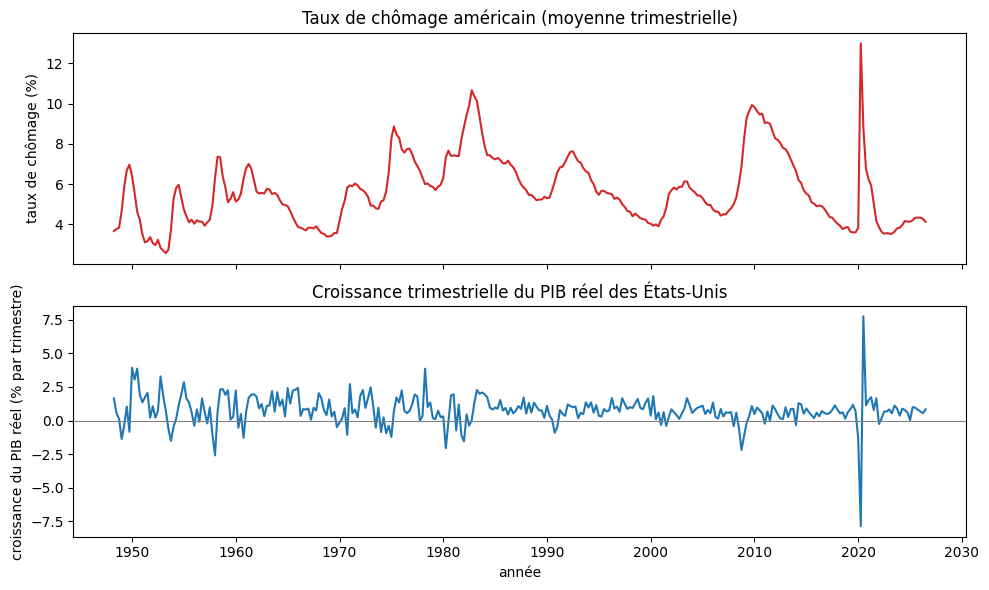

In [5]:
# Graphique 1 : les deux séries dans le temps
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(df.index, df['u'], color='tab:red'); axes[0].set_ylabel('taux de chômage (%)')
axes[0].set_title('Taux de chômage américain (moyenne trimestrielle)')
axes[1].plot(df.index, df['g'], color='tab:blue'); axes[1].axhline(0, color='gray', lw=.8)
axes[1].set_ylabel('croissance du PIB réel (% par trimestre)'); axes[1].set_xlabel('année')
axes[1].set_title('Croissance trimestrielle du PIB réel des États-Unis')
plt.tight_layout(); plt.savefig(FIG / 'g1_series.png', dpi=150); plt.show()

**Interprétation du graphique 1 :** *À compléter après exécution du code sur les données réelles.* (À regarder : le chômage monte-t-il quand la croissance devient négative ? Quel trimestre sort nettement de l'échelle ?)

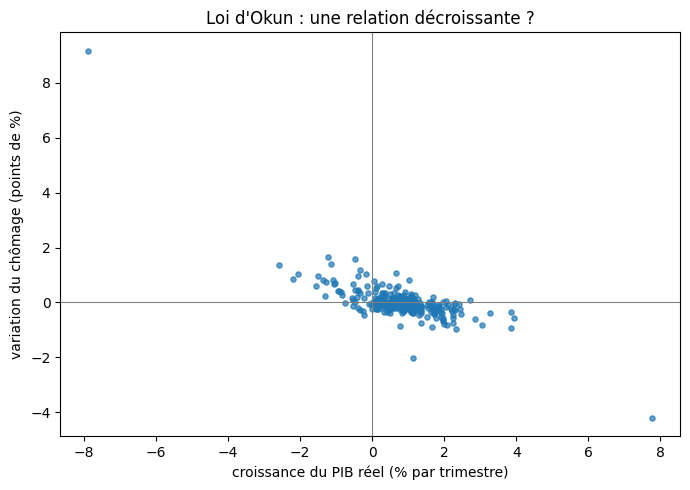

Corrélation g / du : -0.753


In [6]:
# Graphique 2 : relation entre croissance et variation du chômage
plt.figure(figsize=(7, 5))
plt.scatter(df['g'], df['du'], s=14, alpha=.7)
plt.axhline(0, color='gray', lw=.8); plt.axvline(0, color='gray', lw=.8)
plt.xlabel('croissance du PIB réel (% par trimestre)'); plt.ylabel('variation du chômage (points de %)')
plt.title("Loi d'Okun : une relation décroissante ?"); plt.tight_layout()
plt.savefig(FIG / 'g2_nuage.png', dpi=150); plt.show()
print('Corrélation g / du :', round(df['g'].corr(df['du']), 3))

**Interprétation du graphique 2 :** *À compléter après exécution du code sur les données réelles.* (À regarder : le sens de la pente, la dispersion, les points isolés.)

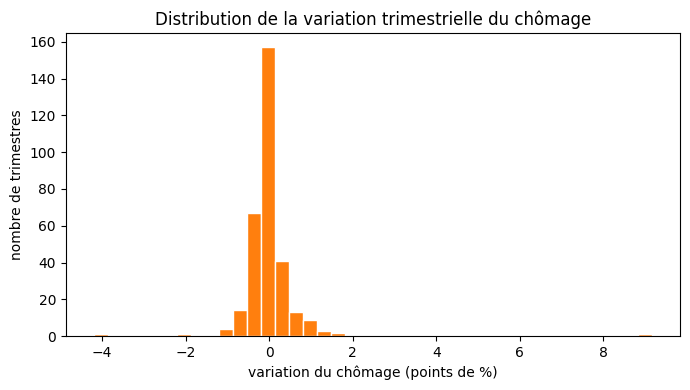

In [7]:
# Graphique 3 : distribution de la variable cible
plt.figure(figsize=(7, 4))
plt.hist(df['du'], bins=40, color='tab:orange', edgecolor='white')
plt.xlabel('variation du chômage (points de %)'); plt.ylabel('nombre de trimestres')
plt.title('Distribution de la variation trimestrielle du chômage'); plt.tight_layout()
plt.savefig(FIG / 'g3_distribution.png', dpi=150); plt.show()

**Interprétation du graphique 3 :** *À compléter après exécution du code sur les données réelles.* (À regarder : symétrie, queue de distribution, effet de 2020.)

## 4. Préparation

- **Valeurs manquantes :** aucune après construction (les lignes sans `shift(1)` sont retirées) ; les trimestres de chômage incomplets sont exclus.
- **Variables créées :** `g` et `du` (formules dans le dictionnaire), construites avec `shift(1)`, donc avec le passé seulement.
- **Encodage :** aucun, toutes les variables sont numériques.
- **Normalisation :** non nécessaire. Il y a un seul prédicteur et la régression linéaire ordinaire n'est pas sensible à l'échelle ; elle servirait seulement pour Ridge ou Lasso.
- **Découpage chronologique, sans mélange aléatoire :** apprentissage de 1948 T2 à 2014 T4, test de 2015 T1 à la dernière date. La validation se fait par `TimeSeriesSplit` à l'intérieur de l'apprentissage. Comme la relation est **contemporaine** (g et du du même trimestre), il n'y a pas d'horizon de prévision et donc pas d'écart à laisser entre apprentissage et test.
- **Prévention des fuites :** aucune transformation ajustée sur toute la série ; le modèle n'est ajusté que sur l'apprentissage ; le test n'est utilisé qu'une fois, à la fin.

In [8]:
DEBUT_TEST = pd.Timestamp('2015-01-01')
train = df[df.index < DEBUT_TEST].copy()
test = df[df.index >= DEBUT_TEST].copy()
X_train, y_train = train[['g']], train['du']
X_test, y_test = test[['g']], test['du']
print('Apprentissage :', train.index.min().date(), 'à', train.index.max().date(), '|', len(train), 'trimestres')
print('Test          :', test.index.min().date(), 'à', test.index.max().date(), '|', len(test), 'trimestres')
assert train.index.max() < test.index.min()   # ordre du temps respecté
df.to_csv(PROC / 'okun_trimestriel.csv')

Apprentissage : 1948-04-01 à 2014-10-01 | 267 trimestres
Test          : 2015-01-01 à 2026-07-01 | 46 trimestres


## 5. Algorithme

**Algorithme principal : régression linéaire (n° 1 du support).** Alternative écartée : l'arbre de régression ou la forêt aléatoire. Avec un seul prédicteur et une relation économique attendue linéaire, un modèle à arbres n'ajoute rien, ne donne pas un coefficient interprétable, et ne sait pas extrapoler hors des valeurs vues (par exemple une récession plus profonde que celles de l'apprentissage).

**Principe.** Le modèle cherche la droite `du = a + b × g` qui rend minimale la somme des carrés des erreurs : `min Σ (du_t − a − b·g_t)²`. Ici `du_t` est la variation du chômage au trimestre t (points de %), `g_t` la croissance du PIB (% par trimestre), `a` l'ordonnée à l'origine (variation du chômage quand la croissance est nulle) et `b` le coefficient d'Okun (points de chômage par point de croissance). **Paramètres appris :** `a` et `b`. **Hyperparamètres :** aucun pour la régression ordinaire, ce qui est un avantage de simplicité ; si on ajoutait une pénalité (Ridge), il y aurait `alpha` (plus il est grand, plus le coefficient est réduit vers 0) et le choix de la normalisation.

**Lecture économique.** On attend `b < 0` : plus la croissance est forte, plus le chômage baisse. La croissance qui laisse le chômage stable vaut `g* = −a / b`.

## 6. Protocole expérimental

- **Références naïves :** (1) moyenne de `du` sur l'apprentissage (`DummyRegressor`) ; (2) dernière valeur observée : on prédit `du_t = du_{t-1}`.
- **Découpage :** apprentissage 1948 T2 à 2014 T4, test à partir de 2015 T1 (une seule utilisation). Validation par `TimeSeriesSplit` (5 plis) dans l'apprentissage ; 0 hyperparamètre réglé, donc 1 configuration essayée.
- **Métrique principale : MAE**, en points de pourcentage de chômage. Elle donne l'erreur moyenne typique, dans l'unité du problème, et reste lisible malgré quelques valeurs extrêmes. **Secondaires :** RMSE (pénalise les grosses erreurs, donc le choc de 2020) et R² (part de variance expliquée ; négatif si le modèle fait pire que la moyenne).
- **Incertitude :** moyenne et écart-type de la MAE sur les 5 plis de validation, et intervalle de confiance à 95 % du coefficient (statsmodels).
- **Seuil de réussite :** MAE du modèle ≤ 0,9 × MAE de la meilleure référence, sur le test.

In [9]:
def metriques(y_vrai, y_pred):
    return {'MAE': mean_absolute_error(y_vrai, y_pred),
            'RMSE': mean_squared_error(y_vrai, y_pred) ** .5,
            'R2': r2_score(y_vrai, y_pred)}

def derniere_valeur(serie):
    # prédiction = valeur du trimestre précédent (shift(1)) ; la première ligne est sans prédiction
    return serie.shift(1).bfill()

# Validation croisée chronologique dans l'apprentissage
cv = TimeSeriesSplit(n_splits=5)
scores = {'Moyenne (référence 1)': [], 'Dernière valeur (référence 2)': [], 'Régression linéaire': []}
for i_app, i_val in cv.split(X_train):
    Xa, ya, Xv, yv = X_train.iloc[i_app], y_train.iloc[i_app], X_train.iloc[i_val], y_train.iloc[i_val]
    scores['Moyenne (référence 1)'].append(mean_absolute_error(yv, DummyRegressor().fit(Xa, ya).predict(Xv)))
    # dernière valeur : on s'appuie sur la série complète décalée d'un cran, donc sur du passé seulement
    scores['Dernière valeur (référence 2)'].append(mean_absolute_error(yv, y_train.shift(1).iloc[i_val]))
    scores['Régression linéaire'].append(mean_absolute_error(yv, LinearRegression().fit(Xa, ya).predict(Xv)))
validation = pd.DataFrame({nom: {'MAE validation (moy.)': np.mean(v), 'MAE validation (écart-type)': np.std(v)} for nom, v in scores.items()}).T
print(validation.round(3))

                               MAE validation (moy.)  \
Moyenne (référence 1)                          0.241   
Dernière valeur (référence 2)                  0.208   
Régression linéaire                            0.203   

                               MAE validation (écart-type)  
Moyenne (référence 1)                                0.039  
Dernière valeur (référence 2)                        0.049  
Régression linéaire                                  0.033  


## 7. Résultats

Le modèle est ajusté sur tout l'apprentissage puis évalué **une seule fois** sur le test.

In [10]:
modele = LinearRegression().fit(X_train, y_train)
ref_moyenne = DummyRegressor().fit(X_train, y_train)

pred_test = {'Moyenne (référence 1)': ref_moyenne.predict(X_test),
             'Dernière valeur (référence 2)': derniere_valeur(pd.concat([y_train, y_test])).loc[y_test.index].values,
             'Régression linéaire': modele.predict(X_test)}
lignes = []
for nom, p in pred_test.items():
    m = metriques(y_test, p)
    lignes.append({'Modèle': nom, 'MAE validation': validation.loc[nom, 'MAE validation (moy.)'],
                   'MAE test': m['MAE'], 'RMSE test': m['RMSE'], 'R² test': m['R2']})
resultats = pd.DataFrame(lignes).set_index('Modèle')
print(resultats.round(3))

mae_ref = min(resultats.loc['Moyenne (référence 1)', 'MAE test'], resultats.loc['Dernière valeur (référence 2)', 'MAE test'])
mae_mod = resultats.loc['Régression linéaire', 'MAE test']
print('\nMAE modèle / MAE meilleure référence =', round(mae_mod / mae_ref, 3), '(objectif : <= 0.90)')
print('Objectif atteint ?', mae_mod <= 0.9 * mae_ref)
print('MAE apprentissage (modèle) =', round(mean_absolute_error(y_train, modele.predict(X_train)), 3), '| MAE test =', round(mae_mod, 3))

                               MAE validation  MAE test  RMSE test  R² test
Modèle                                                                     
Moyenne (référence 1)                   0.241     0.489      1.536   -0.001
Dernière valeur (référence 2)           0.208     0.688      2.408   -1.460
Régression linéaire                     0.203     0.425      1.114    0.473

MAE modèle / MAE meilleure référence = 0.868 (objectif : <= 0.90)
Objectif atteint ? True
MAE apprentissage (modèle) = 0.212 | MAE test = 0.425


**Interprétation du tableau :** *À compléter après exécution du code sur les données réelles.* (À dire : quel modèle a la plus petite MAE, de combien par rapport à la référence, si l'objectif de 10 % est atteint, et si l'écart apprentissage / test montre un problème. Un R² négatif signifie que le modèle fait pire que la moyenne.)

In [11]:
# Coefficient d'Okun et intervalle de confiance (apprentissage seulement)
ols = sm.OLS(y_train, sm.add_constant(X_train)).fit()
a, b = ols.params['const'], ols.params['g']
ic = ols.conf_int()
print(f'a = {a:.3f} pp | b = {b:.3f} pp par point de croissance | IC95% de b = [{ic.loc["g", 0]:.3f} ; {ic.loc["g", 1]:.3f}] | R2 (apprentissage) = {ols.rsquared:.3f}')
print(f'Croissance qui stabilise le chômage g* = -a/b = {-a / b:.2f} % par trimestre')
assert abs(b - modele.coef_[0]) < 1e-9   # même droite que scikit-learn

a = 0.232 pp | b = -0.281 pp par point de croissance | IC95% de b = [-0.317 ; -0.245] | R2 (apprentissage) = 0.476
Croissance qui stabilise le chômage g* = -a/b = 0.82 % par trimestre


**Interprétation des coefficients :** *À compléter après exécution du code sur les données réelles.* (À dire : signe et taille de `b` en points de chômage, ce que veut dire `g*` en croissance annuelle approximative, la largeur de l'intervalle. Une corrélation n'est pas une causalité.)

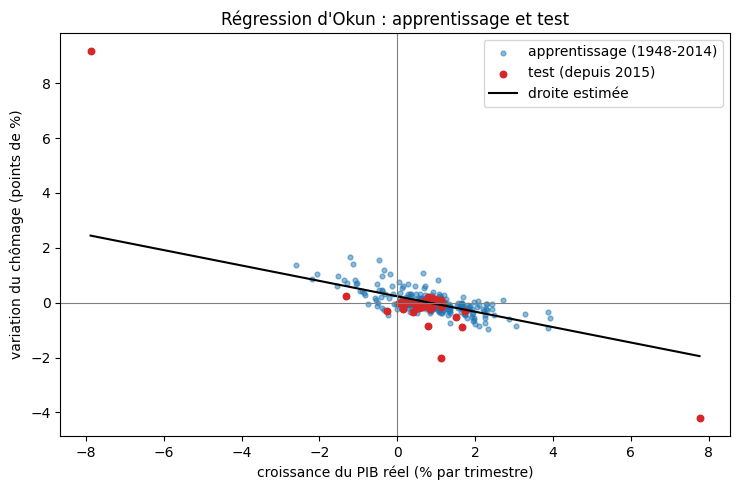

In [12]:
# Graphique 4 : droite estimée, apprentissage et test
plt.figure(figsize=(7.5, 5))
plt.scatter(train['g'], train['du'], s=12, alpha=.5, label='apprentissage (1948-2014)')
plt.scatter(test['g'], test['du'], s=22, color='tab:red', label='test (depuis 2015)')
grille = np.linspace(df['g'].min(), df['g'].max(), 100).reshape(-1, 1)
plt.plot(grille, modele.predict(pd.DataFrame(grille, columns=['g'])), color='black', label='droite estimée')
plt.axhline(0, color='gray', lw=.8); plt.axvline(0, color='gray', lw=.8)
plt.xlabel('croissance du PIB réel (% par trimestre)'); plt.ylabel('variation du chômage (points de %)')
plt.title("Régression d'Okun : apprentissage et test"); plt.legend(); plt.tight_layout()
plt.savefig(FIG / 'g4_droite.png', dpi=150); plt.show()

**Interprétation du graphique 4 :** *À compléter après exécution du code sur les données réelles.* (À regarder : les points rouges suivent-ils la droite ? Quel point est très loin ?)

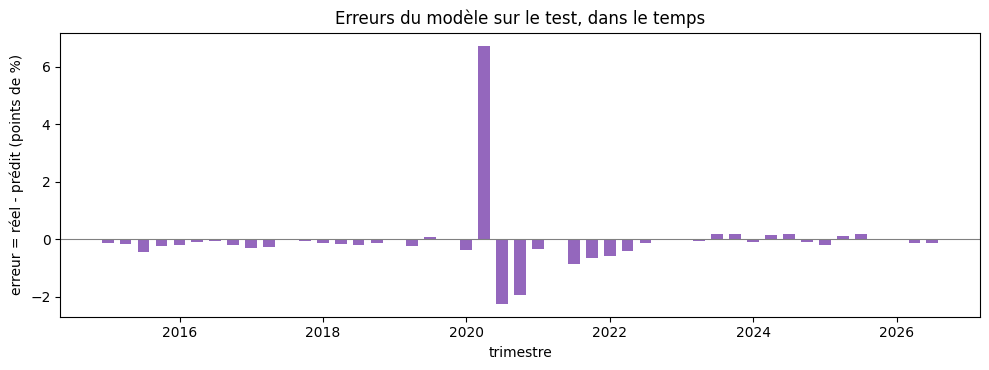

Les 5 plus grosses erreurs (en valeur absolue) :
               g    du  prediction  erreur
date                                      
2020-04-01 -7.88  9.17        2.44    6.72
2020-07-01  7.76 -4.20       -1.95   -2.25
2020-10-01  1.13 -2.03       -0.09   -1.95
2021-07-01  0.78 -0.87        0.01   -0.88
2021-10-01  1.66 -0.90       -0.24   -0.66


In [13]:
# Analyse des erreurs sur le test : résidus dans le temps et pires cas
test_err = test.assign(prediction=modele.predict(X_test))
test_err['erreur'] = test_err['du'] - test_err['prediction']
plt.figure(figsize=(10, 3.8))
plt.bar(test_err.index, test_err['erreur'], width=60, color='tab:purple')
plt.axhline(0, color='gray', lw=.8)
plt.xlabel('trimestre'); plt.ylabel('erreur = réel - prédit (points de %)')
plt.title('Erreurs du modèle sur le test, dans le temps'); plt.tight_layout()
plt.savefig(FIG / 'g5_erreurs.png', dpi=150); plt.show()
print('Les 5 plus grosses erreurs (en valeur absolue) :')
print(test_err.reindex(test_err['erreur'].abs().sort_values(ascending=False).index)[['g', 'du', 'prediction', 'erreur']].head(5).round(2))

**Interprétation des erreurs :** *À compléter après exécution du code sur les données réelles.* (À dire : quels trimestres sont les plus mal prédits et pourquoi, par exemple le choc de 2020 : des chiffres plus forts que tout ce qu'une droite estimée sur 1948-2014 peut produire.)

In [14]:
# Sensibilité : même évaluation sans les trimestres de 2020 (T2 et T3) -- information complémentaire, pas un réglage
masque = ~test.index.isin(pd.to_datetime(['2020-04-01', '2020-07-01']))
lignes = []
for nom, p in pred_test.items():
    m = metriques(y_test[masque], pd.Series(p, index=y_test.index)[masque])
    lignes.append({'Modèle': nom, 'MAE test sans 2020 T2-T3': m['MAE'], 'RMSE': m['RMSE'], 'R²': m['R2']})
print(pd.DataFrame(lignes).set_index('Modèle').round(3))

                               MAE test sans 2020 T2-T3   RMSE     R²
Modèle                                                               
Moyenne (référence 1)                             0.208  0.397 -0.182
Dernière valeur (référence 2)                     0.212  0.436 -0.424
Régression linéaire                               0.240  0.395 -0.169


  Période  trimestres      b  IC95% bas  IC95% haut
1948-1969          87 -0.293     -0.351      -0.236
1970-1989          80 -0.288     -0.351      -0.225
1990-2014         100 -0.273     -0.351      -0.194


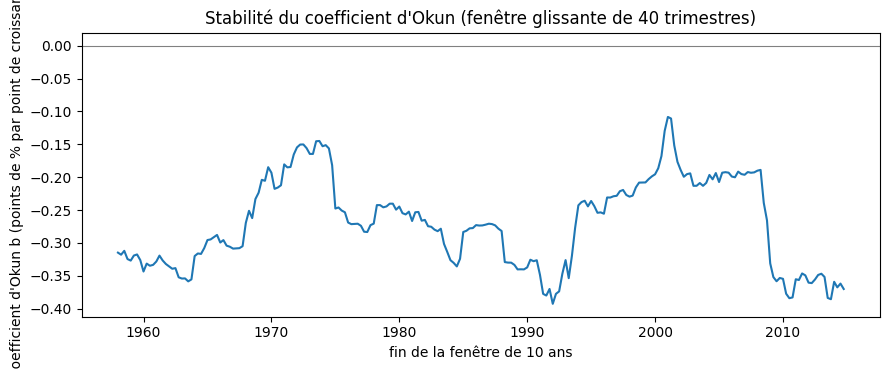

In [15]:
# Stabilité du coefficient d'Okun dans le temps (apprentissage seulement)
periodes = [('1948-1969', '1948-01-01', '1969-12-31'), ('1970-1989', '1970-01-01', '1989-12-31'), ('1990-2014', '1990-01-01', '2014-12-31')]
lignes = []
for nom, d0, d1 in periodes:
    sous = train.loc[d0:d1]
    r = sm.OLS(sous['du'], sm.add_constant(sous[['g']])).fit()
    lignes.append({'Période': nom, 'trimestres': len(sous), 'b': r.params['g'], 'IC95% bas': r.conf_int().loc['g', 0], 'IC95% haut': r.conf_int().loc['g', 1]})
print(pd.DataFrame(lignes).round(3).to_string(index=False))

# Coefficient glissant sur 40 trimestres (10 ans)
fenetre = 40
glissant = pd.Series([np.polyfit(train['g'].iloc[i - fenetre:i], train['du'].iloc[i - fenetre:i], 1)[0] for i in range(fenetre, len(train) + 1)],
                     index=train.index[fenetre - 1:])
plt.figure(figsize=(9, 3.8)); plt.plot(glissant.index, glissant.values)
plt.axhline(0, color='gray', lw=.8)
plt.xlabel('fin de la fenêtre de 10 ans'); plt.ylabel("coefficient d'Okun b (points de % par point de croissance)")
plt.title("Stabilité du coefficient d'Okun (fenêtre glissante de 40 trimestres)"); plt.tight_layout()
plt.savefig(FIG / 'g6_stabilite.png', dpi=150); plt.show()

**Interprétation de la stabilité :** *À compléter après exécution du code sur les données réelles.* (À dire : le coefficient est-il stable, ou change-t-il selon les périodes ? Les intervalles se chevauchent-ils ?)

In [16]:
# Illustration sur 4 trimestres du test (non utilisés pour l'apprentissage)
choix = np.linspace(0, len(test_err) - 1, 4).astype(int)
illustration = test_err.iloc[choix][['g', 'du', 'prediction', 'erreur']].round(2)
illustration.columns = ['croissance g (%)', 'du réel (pp)', 'du prédit (pp)', 'erreur (pp)']
print(illustration)

            croissance g (%)  du réel (pp)  du prédit (pp)  erreur (pp)
date                                                                   
2015-01-01              0.90         -0.17           -0.02        -0.15
2018-10-01              0.14          0.07            0.19        -0.13
2022-07-01              0.67         -0.10            0.04        -0.14
2026-07-01              0.83         -0.13           -0.00        -0.13


**Commentaire de l'illustration :** *À compléter après exécution du code sur les données réelles.* (Pour chacun des 4 trimestres : croissance donnée, chômage prédit, chômage réel, et pourquoi l'écart est petit ou grand.)

## 8. Analyse critique

*À compléter après exécution du code sur les données réelles.*

*Pistes à développer à partir des résultats (limites réelles) :*
- les valeurs du PIB sont révisées : les données utilisées ne sont pas celles que voyait l'analyste à l'époque ;
- la relation est contemporaine : ce modèle décrit la relation mais ne prévoit pas le chômage à l'avance ;
- un seul prédicteur ; les chocs de 2008-2009 et de 2020 ne ressemblent pas à des cycles ordinaires ;
- *piste d'amélioration concrète :* ajouter la croissance retardée (`g.shift(1)`) pour un vrai modèle de prévision, comparer à Ridge, et refaire l'étude avec les versions historiques d'ALFRED.

## 9. Conclusion

*À compléter après exécution du code sur les données réelles.*

*Structure conseillée (3 à 5 lignes) :* répondre directement à la problématique : le modèle bat-il les références, avec quel écart relatif, l'objectif de 10 % est-il atteint, et le coefficient est-il stable ? Terminer par la limite principale.